# 2D Linear Autonomous Systems

**References:** `Notes/lec11.pdf` (Lecture 11), `Notes/Problem Set II.pdf` (Q3), `Notes/tutorial_10_10_26.pdf`

## Concept & Classification
A 2D linear system has the form $\frac{dX}{dt} = J X$, where $X = \begin{pmatrix} u \\ v \end{pmatrix}$ and $J = \begin{pmatrix} a & b \\ c & d \end{pmatrix}$.

Find eigenvalues $\lambda_1, \lambda_2$ from $\det(J - \lambda I) = 0$ (or `np.linalg.eig(J)`). The fixed point $(0, 0)$ is classified by $\lambda_1, \lambda_2$:
- **Real, both $< 0$:** Stable node (all paths go into $(0,0)$).
- **Real, both $> 0$:** Unstable node (all paths leave $(0,0)$).
- **Real, opposite signs ($\lambda_1 > 0, \lambda_2 < 0$):** Saddle point (unstable overall; approaches along $\lambda < 0$ eigenvector, leaves along $\lambda > 0$ eigenvector).
- **Complex ($\alpha \pm i\beta$):**
  - $\alpha < 0 \implies$ Stable spiral (inward).
  - $\alpha > 0 \implies$ Unstable spiral (outward).
  - $\alpha = 0$ (pure imaginary $\pm i\beta$) $\implies$ Center (closed loops).
- **Numerical Limitation:** For a **Center**, Simple Euler spirals outward artificially ($|1 \pm i\beta\Delta t| > 1$), so use RK4 or a smaller step size.

*Professor code: None provided specifically for 2D matrix systems (uses standard RK4/Euler loops).*

Eigenvalues: [-0.2+1.j -0.2-1.j]


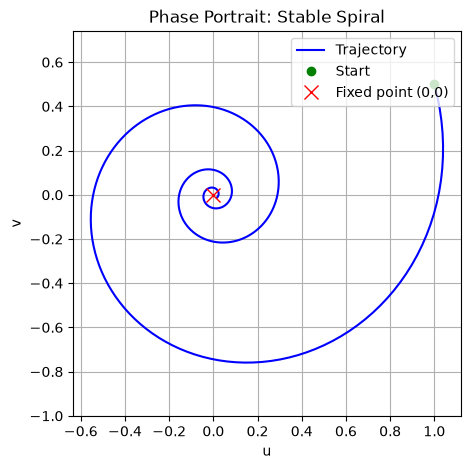

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Example 1: Stable Spiral -> J = [[-0.2, 1], [-1, -0.2]]
J = np.array([[-0.2, 1.0],
              [-1.0, -0.2]])
eigvals, eigvecs = np.linalg.eig(J)
print('Eigenvalues:', eigvals)

dt = 0.05
t = np.arange(0, 20, dt)
n = len(t)
X = np.zeros((2, n))
X[:, 0] = [1.0, 0.5]

for i in range(n - 1):
    k1 = J @ X[:, i]
    k2 = J @ (X[:, i] + 0.5 * dt * k1)
    k3 = J @ (X[:, i] + 0.5 * dt * k2)
    k4 = J @ (X[:, i] + dt * k3)
    X[:, i + 1] = X[:, i] + dt * (k1 + 2*k2 + 2*k3 + k4) / 6

plt.figure(figsize=(5, 5))
plt.plot(X[0], X[1], 'b-', label='Trajectory')
plt.plot(X[0, 0], X[1, 0], 'go', label='Start')
plt.plot(0, 0, 'rx', markersize=10, label='Fixed point (0,0)')
plt.xlabel('u')
plt.ylabel('v')
plt.title('Phase Portrait: Stable Spiral')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()

Center Eigenvalues: [0.+1.j 0.-1.j]


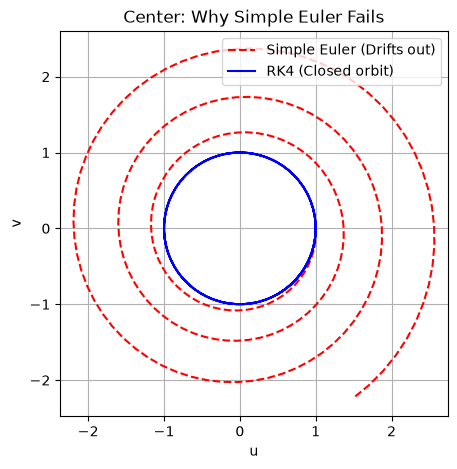

In [2]:
# Example 2: Center -> J = [[0, 1], [-1, 0]] (Simple Euler spirals out, RK4 stays closed)
J_center = np.array([[0.0, 1.0],
                     [-1.0, 0.0]])
print('Center Eigenvalues:', np.linalg.eigvals(J_center))

dt = 0.1
t = np.arange(0, 20, dt)
n = len(t)

X_eu = np.zeros((2, n))
X_rk = np.zeros((2, n))
X_eu[:, 0] = [1.0, 0.0]
X_rk[:, 0] = [1.0, 0.0]

for i in range(n - 1):
    # Simple Euler
    X_eu[:, i + 1] = X_eu[:, i] + dt * (J_center @ X_eu[:, i])
    # RK4
    k1 = J_center @ X_rk[:, i]
    k2 = J_center @ (X_rk[:, i] + 0.5 * dt * k1)
    k3 = J_center @ (X_rk[:, i] + 0.5 * dt * k2)
    k4 = J_center @ (X_rk[:, i] + dt * k3)
    X_rk[:, i + 1] = X_rk[:, i] + dt * (k1 + 2*k2 + 2*k3 + k4) / 6

plt.figure(figsize=(5, 5))
plt.plot(X_eu[0], X_eu[1], 'r--', label='Simple Euler (Drifts out)')
plt.plot(X_rk[0], X_rk[1], 'b-', label='RK4 (Closed orbit)')
plt.xlabel('u')
plt.ylabel('v')
plt.title('Center: Why Simple Euler Fails')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()